In [1]:
import xspec
import numpy as np
import os
import subprocess
import matplotlib.pyplot as plt
import re
import pandas as pd
from astropy.io import fits

In [2]:
# Enter directory where spectra are stored

path_spectra='/work2/sruedavargas/Results_Sy2/NGC_5506/products/spectra_files'
os.chdir(path_spectra)

# Enter name of the binned PN GTI table for the observation to be fitted 

bin_gti='bin_gti_0201830401_PN_cons.fits'

In [3]:
xchat = xspec.Xset.chatter, xspec.Xset.logChatter
xspec.Xset.chatter    = 0
xspec.Xset.logChatter = 0

In [4]:
# xspec.Xset.chatter, xspec.Xset.logChatter = xchat

In [5]:
xspec.AllData.clear()

In [6]:
mos1_12_data = 'av_spec_0201830401_MOS1_cons_pat12_src_grp20.ds'
mos2_12_data = 'av_spec_0201830401_MOS2_cons_pat12_src_grp20.ds'
pn_0_data = 'av_spec_0201830401_PN_cons_pat0_src_grp20.ds'
pn_14_data = 'av_spec_0201830401_PN_cons_pat14_src_grp20.ds'

In [7]:
# Let's do it for just one observation and then I generalize it.
# I'll use observation 0761220101 conservative



xspec.AllData(f"1:1 {mos1_12_data} 2:2 {mos2_12_data} 3:3 {pn_0_data} 4:4 {pn_14_data} ")

xspec.AllData.notice('all')
xspec.AllData.ignore('bad')

# evince_mos1=[f"evince epatplot_0554170201_MOS1_cons.ps"]
# subprocess.call(evince_mos1, shell=True)

# low_mos1=input('Lower energy limit MOS1:')
# up_mos1=input('Upper energy limit MOS1:')

# evince_mos2=[f"evince epatplot_0554170201_MOS2_cons.ps"]
# subprocess.call(evince_mos2, shell=True)
# low_mos2=input('Lower energy limit MOS2:')
# up_mos2=input('Upper energy limit MOS2:')


# evince_pn=[f"evince epatplot_0554170201_PN_cons.ps"]
# subprocess.call(evince_pn, shell=True)
# low_pn_0=input('Lower energy limit PN pattern 0:')
# up_pn_0=input('Upper energy limit PN pattern 0:')
# low_pn_14=input('Lower energy limit PN pattern 1-4:')
# up_pn_14=input('Upper energy limit PN pattern 1-4:')

low_mos1=0.2
up_mos1=6.0
low_mos2=0.2
up_mos2=7.0
low_pn_0=0.2
up_pn_0=9.0
low_pn_14=0.65
up_pn_14=9.0



xspec.AllData(1).ignore(f"**-{low_mos1} {up_mos1}-**")
xspec.AllData(2).ignore(f"**-{low_mos2} {up_mos2}-**")
xspec.AllData(3).ignore(f"**-{low_pn_0} {up_pn_0}-**")
xspec.AllData(4).ignore(f"**-{low_pn_14} {up_pn_14}-**")


***Warning: Detected response matrix energy bin value = 0 (or neg).
     XSPEC will instead use small finite value (response file will not be altered).
***Warning: Detected response matrix energy bin value = 0 (or neg).
     XSPEC will instead use small finite value (response file will not be altered).

4 spectra  in use
 
Spectral Data File: av_spec_0201830401_MOS1_cons_pat12_src_grp20.ds  Spectrum 1
Net count rate (cts/s) for Spectrum:1  2.518e+00 +/- 1.295e-02 (99.6 % total)
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-1091
  Telescope: XMM Instrument: EMOS1  Channel Type: PI
  Exposure Time: 1.508e+04 sec
 Using fit statistic: chi
 Using Background File                av_spec_0201830401_MOS1_cons_pat12_bgd.ds
  Background Exposure Time: 1.526e+04 sec
 Using Response (RMF) File            av_spec_0201830401_MOS1_cons_pat12_src.rmf for Source 1
 Using Auxiliary Response (ARF) File  av_spec_0201830401_MOS1_cons_pat12_src.arf

Spectral Data File: av_spec_0201830401

In [8]:
xspec.Xset.abund = 'wilm' 
xspec.Xset.xsect = 'vern' 
xspec.Xset.cosmo = '70 0 0.73'

 Solar Abundance Vector set to wilm:  Wilms, J., Allen, A. & McCray, R. ApJ 542 914 (2000) (abundances are set to zero for those elements not included in the paper).
 Cross Section Table set to vern:  Verner, Ferland, Korista, and Yakovlev 1996


In [9]:
# Setting redshift and galactic nH from Laha

z_opt = 0.0061 # from Laha
nH    = 4.08e-2 # in units of 10^22 cm^-2

In [10]:
# Defining model taken from Laha for NGC 5506

xspec.AllModels += ("constant(TBabs*(zTBabs*(apec+powerlaw)+zgauss+zTBabs*(pexrav+zgauss+zgauss)))")
mod1 = xspec.AllModels(1)



Model constant<1>(TBabs<2>(zTBabs<3>(apec<4> + powerlaw<5>) + zgauss<6> + zTBabs<7>(pexrav<8> + zgauss<9> + zgauss<10>))) Source No.: 1   Active/On
Model Model Component  Parameter  Unit     Value
 par  comp
                           Data group: 1
   1    1   constant   factor              1.00000      +/-  0.0          
   2    2   TBabs      nH         10^22    1.00000      +/-  0.0          
   3    3   zTBabs     nH         10^22    1.00000      +/-  0.0          
   4    3   zTBabs     Redshift            0.0          frozen
   5    4   apec       kT         keV      1.00000      +/-  0.0          
   6    4   apec       Abundanc            1.00000      frozen
   7    4   apec       Redshift            0.0          frozen
   8    4   apec       norm                1.00000      +/-  0.0          
   9    5   powerlaw   PhoIndex            1.00000      +/-  0.0          
  10    5   powerlaw   norm                1.00000      +/-  0.0          
  11    6   zgauss     LineE      ke

tbvabs Version 2.3
Cosmic absorption with grains and H2, modified from
Wilms, Allen, & McCray, 2000, ApJ 542, 914-924
Questions: Joern Wilms
joern.wilms@sternwarte.uni-erlangen.de
joern.wilms@fau.de

http://pulsar.sternwarte.uni-erlangen.de/wilms/research/tbabs/

PLEASE NOTICE:
To get the model described by the above paper
you will also have to set the abundances:
   abund wilm

Note that this routine ignores the current cross section setting
as it always HAS to use the Verner cross sections as a baseline.


In [11]:
mod1.constant.factor.values=(1,-1)

mod1.TBabs.nH.values = (nH, -1)

mod1.zTBabs.nH.values = (0.0846928, 0.01, 0, 0, 1e+5, 1e+5)  
mod1.zTBabs.Redshift.values = (z_opt, -1)

mod1.apec.kT.values = (0.8861671, -1) #f
mod1.apec.Abundanc. values = (1, -1)
mod1.apec.Redshift.values = (z_opt, -1)
mod1.apec.norm.values = (3.14725e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.powerlaw.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 1.99)
mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex
mod1.powerlaw.norm.values = (0.0003498589, 0.01, 0, 0, 1e+10, 1e+10)

mod1.zgauss.LineE.values = (0.5657432, -1) #f
mod1.zgauss.Sigma.values = (0, -1) #f 
mod1.zgauss.Redshift.values = (0, -1)
mod1.zgauss.norm.values = (1.627922e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.zTBabs_7.nH.values = (2.761, 0.1, 0, 0, 100000, 100000)
mod1.zTBabs_7.Redshift.values = (z_opt, -1)

mod1.pexrav.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 5)
mod1.pexrav.foldE.values = (100., -1)
mod1.pexrav.rel_refl.values = (2, -1)
mod1.pexrav.Redshift.values = (nH, -1)
mod1.pexrav.abund.values = (1,-1)
mod1.pexrav.Fe_abund.values = (1, -1)
mod1.pexrav.cosIncl.values = (0.45, -1)
mod1.pexrav.norm.values = (0.01804564, 0.01, 0, 0, 1e+10, 1e+10)

mod1.zgauss_9.LineE.values = (6.363523, -1) #f
mod1.zgauss_9.Sigma.values = (0, -1) #f
mod1.zgauss_9.Redshift.values = (nH, -1)
mod1.zgauss_9.norm.values = (4.28059e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.zgauss_10.LineE.values = (6.64431, -1) #f
mod1.zgauss_10.Sigma.values = (0.2, -1) #f
mod1.zgauss_10.Redshift.values = (nH, -1)
mod1.zgauss_10.norm.values = (6.47984e-05, 0.01, 0, 0, 1e+10, 1e+10) 

xspec.AllModels(2).constant.factor.untie()
xspec.AllModels(2).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
xspec.AllModels(3).constant.factor.untie()
xspec.AllModels(3).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
xspec.AllModels(4).constant.factor.untie()
xspec.AllModels(4).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)

xspec.AllModels.show()


Fit statistic  : Chi-Squared              2.218519e+09     using 929 bins, spectrum 1, group 1.
                 Chi-Squared              5.856429e+10     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              1.226668e+11     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              7.145155e+10     using 963 bins, spectrum 4, group 4.
Total fit statistic                       2.549012e+11     with 4161 d.o.f.

Test statistic : Chi-Squared              2.549012e+11     using 4181 bins.
 Null hypothesis probability of 0.000000e+00 with 4161 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared              5.839080e+09     using 929 bins, spectrum 1, group 1.
                 Chi-Squared              6.293493e+10     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              1.303903e+11     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              7.517800e+10     u

                 Chi-Squared              2.360298e+10     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              4.991686e+10     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              2.891619e+10     using 963 bins, spectrum 4, group 4.
Total fit statistic                       1.025372e+11     with 4166 d.o.f.

Test statistic : Chi-Squared              1.025372e+11     using 4181 bins.
 Null hypothesis probability of 0.000000e+00 with 4166 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared              1.036200e+08     using 929 bins, spectrum 1, group 1.
                 Chi-Squared              2.363091e+10     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              4.997453e+10     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              2.894930e+10     using 963 bins, spectrum 4, group 4.
Total fit statistic                       1.026584e+11     wi


Fit statistic  : Chi-Squared                358485.8     using 929 bins, spectrum 1, group 1.
                 Chi-Squared              5.983506e+09     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              1.336114e+10     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              7.697490e+09     using 963 bins, spectrum 4, group 4.
Total fit statistic                       2.704249e+10     with 4171 d.o.f.

Test statistic : Chi-Squared              2.704249e+10     using 4181 bins.
 Null hypothesis probability of 0.000000e+00 with 4171 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                631260.1     using 929 bins, spectrum 1, group 1.
                 Chi-Squared              3.445487e+09     using 979 bins, spectrum 2, group 2.
                 Chi-Squared              7.510051e+09     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared              4.763758e+09     using

In [12]:
xspec.Fit.statMethod = "chi"

Default fit statistic is set to: Chi-Squared
   This will apply to all current and newly loaded spectra.

Fit statistic  : Chi-Squared                 6972.10     using 929 bins, spectrum 1, group 1.
                 Chi-Squared                 5728.92     using 979 bins, spectrum 2, group 2.
                 Chi-Squared                 8464.90     using 1310 bins, spectrum 3, group 3.
                 Chi-Squared                 4994.14     using 963 bins, spectrum 4, group 4.
Total fit statistic                         26160.06     with 4169 d.o.f.

Test statistic : Chi-Squared                26160.06     using 4181 bins.
 Null hypothesis probability of 0.00e+00 with 4169 degrees of freedom
 Current data and model not fit yet.


In [13]:
# xspec.Xset.chatter, xspec.Xset.logChatter = xchat
xspec.Fit.perform()

                                   Parameters
Chi-Squared  |beta|/N    Lvl          3:nH        8:norm       10:norm       14:norm         15:nH   17:PhoIndex       24:norm       28:norm       32:norm     33:factor     65:factor     97:factor
4937.76      383520       -3      0.165459   1.81860e-05   0.000477688   1.58951e-06       3.84374       1.72218     0.0158483   7.90853e-06   7.06084e-05       1.02451       1.00764      0.956415
4543.8       218696       -4      0.145526   1.47991e-05   0.000417701   7.35377e-07       4.48894       1.90798     0.0209039   2.20952e-06   9.02078e-05       1.02330       1.00982      0.959822
4375.94      49583.9      -5      0.133074   2.19928e-05   0.000390673   2.11637e-07       4.51364       1.91578     0.0220564   6.21306e-08   9.07349e-05       1.02297       1.01033      0.959855
4375.79      54275.4      -1      0.132099   2.20170e-05   0.000389778   1.01654e-07       4.51239       1.91566     0.0220617   9.58525e-09   8.98327e-05       1.023

In [14]:
xspec.Fit.perform()

                                   Parameters
Chi-Squared  |beta|/N    Lvl          3:nH        8:norm       10:norm       14:norm         15:nH   17:PhoIndex       24:norm       28:norm       32:norm     33:factor     65:factor     97:factor
4375.11      52447.3       0      0.131550   2.25538e-05   0.000387713   5.24364e-09       4.50941       1.91551     0.0220404   5.54109e-10   8.77031e-05       1.02308       1.01032      0.959857
4374.91      51025.7       0      0.131799   2.27509e-05   0.000387611   1.97063e-09       4.50872       1.91548     0.0220426   1.29763e-10   8.66550e-05       1.02308       1.01030      0.959846
4374.81      50105.1       0      0.131968   2.29293e-05   0.000387516   3.86593e-10       4.50840       1.91546     0.0220439   2.45185e-11   8.60955e-05       1.02305       1.01028      0.959820
4374.76      49568.5       0      0.132086   2.30830e-05   0.000387432   1.93244e-10       4.50824       1.91546     0.0220447   1.14198e-11   8.57991e-05       1.023

In [15]:
xspec.Fit.perform()

                                   Parameters
Chi-Squared  |beta|/N    Lvl          3:nH        8:norm       10:norm       14:norm         15:nH   17:PhoIndex       24:norm       28:norm       32:norm     33:factor     65:factor     97:factor
4374.6       48221.4       0      0.132340   2.34794e-05   0.000386927   7.24883e-15       4.50784       1.91546     0.0220342   1.07909e-13   8.51282e-05       1.02293       1.01017      0.959705
4374.57      47936         0      0.132386   2.34966e-05   0.000386915   3.33845e-15       4.50766       1.91546     0.0220346   3.53491e-14   8.48371e-05       1.02294       1.01016      0.959699
4374.54      47678.7       0      0.132430   2.35149e-05   0.000386905   1.40050e-15       4.50751       1.91546     0.0220349   1.72852e-14   8.45718e-05       1.02294       1.01016      0.959694
4374.51      47445.5       0      0.132471   2.35340e-05   0.000386894   4.39537e-16       4.50736       1.91546     0.0220352   8.28775e-15   8.43298e-05       1.022

In [16]:
av_nh_val=mod1.zTBabs_7.nH.values[0]
av_gamma_val=mod1.pexrav.PhoIndex.values[0]

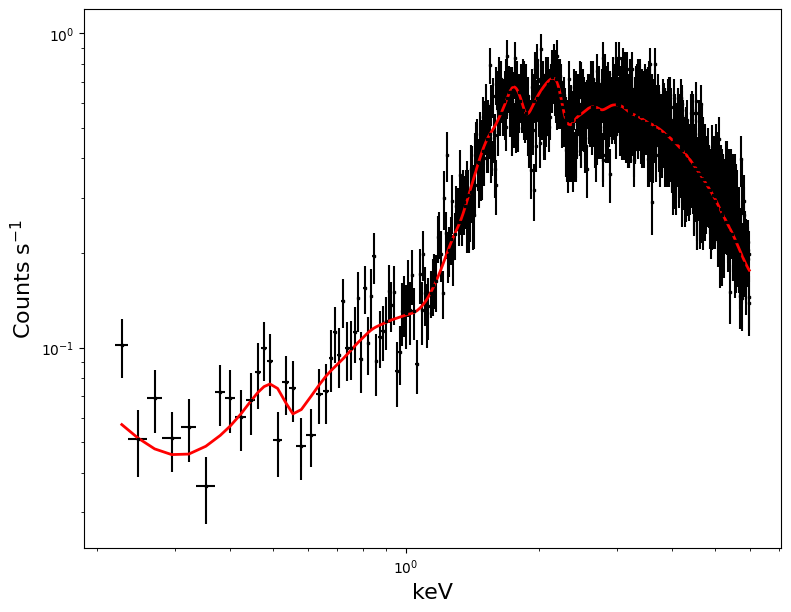

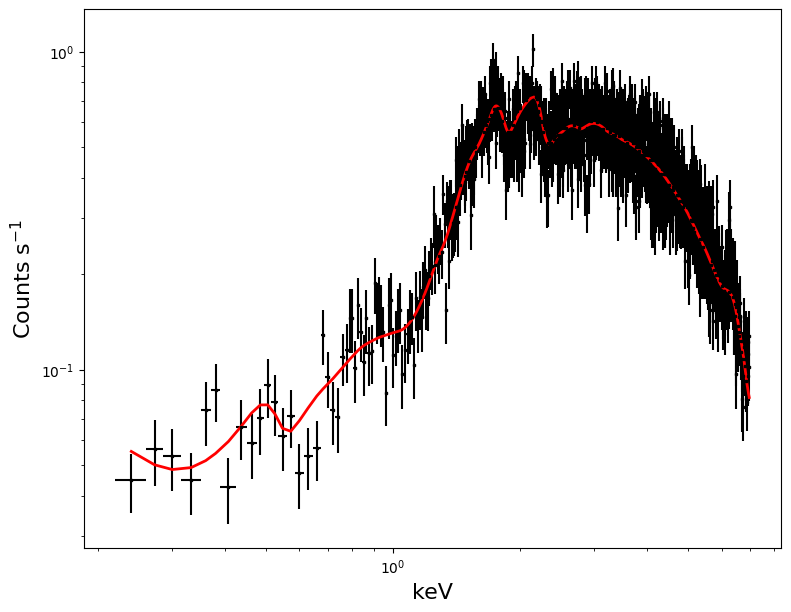

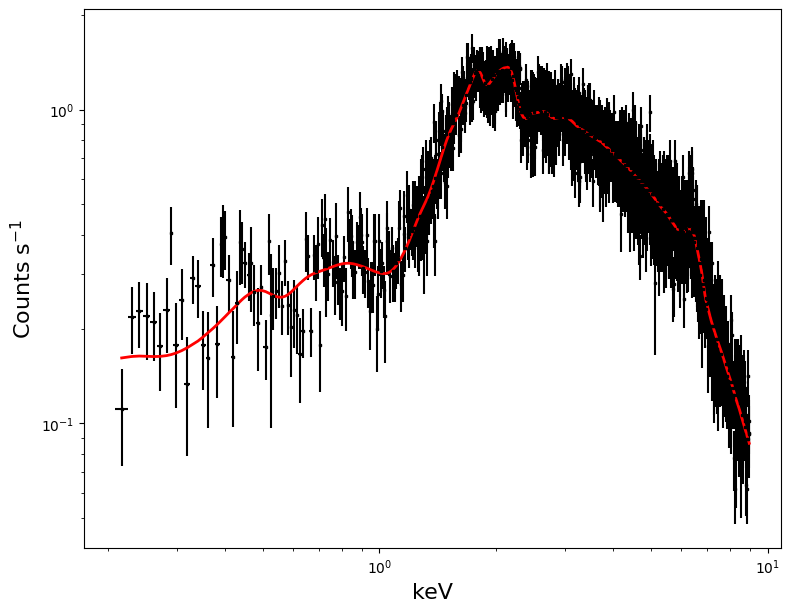

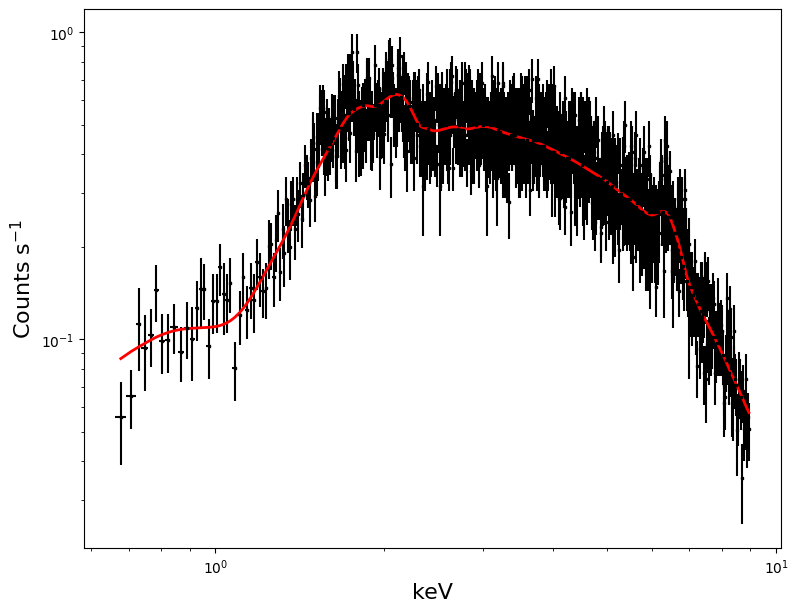

In [17]:
for ii in range(1,5):


    xspec.Plot.xAxis = "keV"


    xspec.Plot('data') 

    x  = xspec.Plot.x(plotGroup=ii)
    xe = xspec.Plot.xErr(plotGroup=ii)
    y  = xspec.Plot.y(plotGroup=ii)
    ye = xspec.Plot.yErr(plotGroup=ii)


    pm = xspec.Plot.model(plotGroup=ii)


    fig,ax = plt.subplots(1,figsize=(9,7))


    ax.errorbar(x,y,xerr=xe,yerr=ye,ls='',
                c='k',markersize=2,marker='s')

    ax.plot(x,pm,c='r',ls='-',lw=2)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('keV',fontsize=16)
    ax.set_ylabel(r'Counts s$^{-1}$',fontsize=16)
    
    fig.savefig(f'spectra_{ii}')

In [18]:
model_values=[]

for ie in range(1,33):
    
    value=mod1(ie).values[0]   
    model_values.append(value)



constant_values=[]

for io in range(2,5):
    value=xspec.AllModels(io).constant.factor.values[0]
    constant_values.append(value)
        

In [19]:

# Fitting single spectra
os.chdir(path_spectra)


mos1_sing_spec=[]
mos2_sing_spec=[]
pn0_sing_spec=[]
pn14_sing_spec=[]

for file in os.listdir():
    if file.startswith('sing_spec_0201830401') and file.endswith('_grp20.ds') and 'cons' in file:
        
        if 'MOS1' in file:
            mos1_sing_spec.append(file)
        elif 'MOS2' in file:
            mos2_sing_spec.append(file)
        elif 'PN' and 'pat0' in file:
            pn0_sing_spec.append(file)
        elif 'PN' and 'pat14' in file:
            pn14_sing_spec.append(file)
              

In [20]:
def sort_key(item):

    match = re.search(r'(\d+)_src', item)
    if match:
        return int(match.group(1))
    return 0


mos1_sing_spec_sorted = sorted(mos1_sing_spec, key=sort_key)
mos2_sing_spec_sorted = sorted(mos2_sing_spec, key=sort_key)
pn0_sing_spec_sorted = sorted(pn0_sing_spec, key=sort_key)
pn14_sing_spec_sorted = sorted(pn14_sing_spec, key=sort_key)


In [21]:
# Recovering averge spectra model values

def ret_model_values():
    
    for ele in zip(range(1,33), model_values):
        mod1(ele[0]).values=(ele[1],-1.)
        
    
    mod1.powerlaw.PhoIndex.frozen = False    
    mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex

        
    for io in zip(range(2,5), constant_values):
        xspec.AllModels(io[0]).constant.factor.values=(io[1],-1)
         
    
#Getting spectra that do not contain data

def empty(spec_set):
    
    data_spec_files=[]
    
    for file in spec_set:
    
        with fits.open(file) as f:
            header_spec = f[1].header
            try:
                a = header_spec['EXPOSURE']
            except:
                print(f"No data in spectrum {file}")
            else:
                data_spec_files.append(file)
                        
    return(data_spec_files)
    

# Writing expression for data based on spectral set 


def data_expression(n_set, spectral_set):
    
    data_spec_expression=""
    n_list=[]
    exp_n_ar=[]
    
    for file in spectral_set:
        
        data_spec_expression+=f"{n_set}:{n_set} {file} "
        exp_n_ar.append((n_set, file))

        n_set+=1
                    
    return(data_spec_expression, exp_n_ar)


#Defining the energy range for each spectrum in the spectral set

def energies_spec(array_spec_set):
    
    for element in array_spec_set:
        
        data_group=element[0]
        spectrum_file=element[1]
        
        if 'MOS1' in spectrum_file:
            
            xspec.AllData(data_group).ignore(f"**-{low_mos1} {up_mos1}-**")
            
        elif 'MOS2' in spectrum_file:
            
            xspec.AllData(data_group).ignore(f"**-{low_mos2} {up_mos2}-**")
            
        elif 'PN' and 'pat0' in spectrum_file:

            xspec.AllData(data_group).ignore(f"**-{low_pn_0} {up_pn_0}-**")
        
        elif 'PN' and 'pat14' in spectrum_file:

            xspec.AllData(data_group).ignore(f"**-{low_pn_14} {up_pn_14}-**")
            



In [22]:
# Fitting for a single bin
# Uncomment lines before to fit average spectra to a single bin, and change the name of the grouped spectra file 
# for that specific bin


# xspec.Xset.chatter, xspec.Xset.logChatter = xchat

# xspec.AllData.clear()



# mos1_12_bin = 'sing_spec_0201830401_MOS1_cons_pat12_6_src_grp20.ds'
# mos2_12_bin = 'sing_spec_0201830401_MOS2_cons_pat12_6_src_grp20.ds'
# pn_0_bin = 'sing_spec_0201830401_PN_cons_pat0_6_src_grp20.ds'
# pn_14_bin = 'sing_spec_0201830401_PN_cons_pat14_6_src_grp20.ds'

# xspec.AllData(f"1:1 {mos1_12_bin} 2:2 {mos2_12_bin} 3:3 {pn_0_bin} 4:4 {pn_14_bin} ")


# xspec.AllData(1).ignore(f"**-{low_mos1} {up_mos1}-**")
# xspec.AllData(2).ignore(f"**-{low_mos2} {up_mos2}-**")
# xspec.AllData(3).ignore(f"**-{low_pn_0} {up_pn_0}-**")
# xspec.AllData(4).ignore(f"**-{low_pn_14} {up_pn_14}-**")


# ret_model_values()

# nh_par=mod1.zTBabs_7.nH
# phoindex=mod1.pexrav.PhoIndex

# values_nh_1=[]
# error_nh_1=[]

# values_pi_2=[]
# error_pi_2=[]
# values_nh_2=[]
# error_nh_2=[]

# mod1(15).frozen = False
# mod1(24).frozen = False
# xspec.Fit.perform()
# values_nh_1.append(nh_par.values[0])
# xspec.Fit.error(f'2.706 15')
# error_nh_1.append(nh_par.error)

# mod1(17).frozen = False
# xspec.Fit.perform()
# values_nh_2.append(nh_par.values[0])
# values_pi_2.append(phoindex.values[0])

# xspec.Fit.error(f'2.706 15')
# xspec.Fit.error(f'2.706 17')

# error_nh_2.append(nh_par.error)
# error_pi_2.append(phoindex.error)


***Warning: Detected response matrix energy bin value = 0 (or neg).
     XSPEC will instead use small finite value (response file will not be altered).
***Warning: Detected response matrix energy bin value = 0 (or neg).
     XSPEC will instead use small finite value (response file will not be altered).

4 spectra  in use
 
Spectral Data File: sing_spec_0201830401_MOS1_cons_pat12_6_src_grp20.ds  Spectrum 1
Net count rate (cts/s) for Spectrum:1  1.366e+00 +/- 4.339e-02 (99.4 % total)
 Assigned to Data Group 1 and Plot Group 1
  Noticed Channels:  1-48
  Telescope: XMM Instrument: EMOS1  Channel Type: PI
  Exposure Time: 729.9 sec
 Using fit statistic: chi
 Using Background File                sing_spec_0201830401_MOS1_cons_pat12_6_bgd.ds
  Background Exposure Time: 1.526e+04 sec
 Using Response (RMF) File            sing_spec_0201830401_MOS1_cons_pat12_6_src.rmf for Source 1
 Using Auxiliary Response (ARF) File  sing_spec_0201830401_MOS1_cons_pat12_6_src.arf

Spectral Data File: sing_spe

                 Chi-Squared                  122.58     using 66 bins, spectrum 4, group 4.
Total fit statistic                          1689.43     with 265 d.o.f.

Test statistic : Chi-Squared                 1689.43     using 272 bins.
 Null hypothesis probability of 1.24e-205 with 265 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                  624.57     using 43 bins, spectrum 1, group 1.
                 Chi-Squared                  815.28     using 38 bins, spectrum 2, group 2.
                 Chi-Squared                  127.00     using 125 bins, spectrum 3, group 3.
                 Chi-Squared                  122.58     using 66 bins, spectrum 4, group 4.
Total fit statistic                          1689.43     with 265 d.o.f.

Test statistic : Chi-Squared                 1689.43     using 272 bins.
 Null hypothesis probability of 1.24e-205 with 265 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squ


Fit statistic  : Chi-Squared                  624.57     using 43 bins, spectrum 1, group 1.
                 Chi-Squared                  815.28     using 38 bins, spectrum 2, group 2.
                 Chi-Squared                  127.00     using 125 bins, spectrum 3, group 3.
                 Chi-Squared                  122.58     using 66 bins, spectrum 4, group 4.
Total fit statistic                          1689.43     with 269 d.o.f.

Test statistic : Chi-Squared                 1689.43     using 272 bins.
 Null hypothesis probability of 5.00e-204 with 269 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                  624.57     using 43 bins, spectrum 1, group 1.
                 Chi-Squared                  815.28     using 38 bins, spectrum 2, group 2.
                 Chi-Squared                  127.00     using 125 bins, spectrum 3, group 3.
                 Chi-Squared                  122.58     using 66 bins, spectrum 4, group 4

Total fit statistic                          1750.55     with 272 d.o.f.

Test statistic : Chi-Squared                 1750.55     using 272 bins.
 Null hypothesis probability of 5.07e-214 with 272 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                  624.57     using 43 bins, spectrum 1, group 1.
                 Chi-Squared                  888.75     using 38 bins, spectrum 2, group 2.
                 Chi-Squared                  130.02     using 125 bins, spectrum 3, group 3.
                 Chi-Squared                  107.21     using 66 bins, spectrum 4, group 4.
Total fit statistic                          1750.55     with 271 d.o.f.

Test statistic : Chi-Squared                 1750.55     using 272 bins.
 Null hypothesis probability of 1.99e-214 with 271 degrees of freedom
 Current data and model not fit yet.

Fit statistic  : Chi-Squared                  624.57     using 43 bins, spectrum 1, group 1.
                 Chi-Squ

Exception: Error executing command: error

In [ ]:
n_expression=1

nh_values_nh_free=[]
nh_error_nh_free=[]


chi2_nh_free=[]
dof_nh_free=[]

flux_02_10=[]
flux_02_2=[]
flux_2_10=[]


nh_values_nhgamma_free=[]
nh_error_nhgamma_free=[]

gamma_values_nhgamma_free=[]
gamma_error_nhgamma_free=[]


chi2_nhgamma_free=[]
dof_nhgamma_free=[]



for spset in zip(mos1_sing_spec_sorted,mos2_sing_spec_sorted,pn0_sing_spec_sorted,pn14_sing_spec_sorted):
    
    xspec.AllData.clear()
    
    use_files=empty(spset)
    expression_funct=data_expression(n_expression, use_files)
    
    data_exp_xspec=expression_funct[0]
    arr_set_en=expression_funct[1]

    xspec.AllData(f"{data_exp_xspec}")

    xspec.AllData.notice('all')
    xspec.AllData.ignore('bad')
    
    energies_spec(arr_set_en)
    
    ret_model_values()
    

    nh_par = mod1.zTBabs_7.nH
    phoindex_par = mod1.pexrav.PhoIndex
 
 #N_H and norm powerlaw free
    
    mod1(15).frozen = False
    mod1(24).frozen = False
    
    xspec.Fit.perform()
    nh_values_nh_free.append(nh_par.values[0])
    
    xspec.Fit.error('2.706 15')
    nh_error_nh_free.append(nh_par.error)
    
    chi2_nh_free_val=xspec.Fit.statistic
    chi2_nh_free.append(chi2_nh_free_val)
    
    dof_nh_free_val=xspec.Fit.dof
    dof_nh_free.append(dof_nh_free_val)
    
    xspec.AllModels.calcFlux('0.2 10.0 err 20 90')
    flux_02_10_val=xspec.AllData(3).flux
    flux_02_10.append(flux_02_10_val)
    
    xspec.AllModels.calcFlux('0.2 2.0 err 20 90')
    flux_02_2_val=xspec.AllData(3).flux
    flux_02_2.append(flux_02_2_val)
    
    xspec.AllModels.calcFlux('2.0 10.0 err 20 90')
    flux_2_10_val=xspec.AllData(3).flux
    flux_2_10.append(flux_2_10_val)
    
        
# N_H, gamma, and norm powerlaw free
    

    mod1(17).frozen = False
    xspec.Fit.perform()
    nh_values_nhgamma_free.append(nh_par.values[0])
    gamma_values_nhgamma_free.append(phoindex_par.values[0])
    
    chi2_nhgamma_free_val=xspec.Fit.statistic
    chi2_nhgamma_free.append(chi2_nhgamma_free_val)
    
    dof_nhgamma_free_val=xspec.Fit.dof
    dof_nhgamma_free.append(dof_nhgamma_free_val)

    xspec.Fit.error('2.706 15')
    nh_error_nhgamma_free.append(nh_par.error)
    
    xspec.Fit.error('2.706 17')
    gamma_error_nhgamma_free.append(phoindex_par.error)
    
    
               

In [ ]:
xspec.Xset.chatter, xspec.Xset.logChatter = xchat

In [ ]:
# Inspecting resulting values

# Results N_H free 

# print('N_H val', nh_values_nh_free)
# print('N_H error',nh_error_nh_free)

# print('chi2_nh_free', chi2_nh_free)
# print('dof_nh_free', dof_nh_free)

# print('flux_02_10', flux_02_10)
# print('flux_02_2', flux_02_2)


# Results N_H and Gamma free 


# print('N_H val (gamma free)', nh_values_nhgamma_free)
# print('N_H error (gamma free)',nh_error_nhgamma_free)


# print('Gamma val (gamma free)', gamma_values_nhgamma_free)
# print('Gamma error (gamma free)', gamma_error_nhgamma_free)


# print('chi2_nhgamma_free', chi2_nhgamma_free)
# print('dof_nhgamma_free', dof_nhgamma_free)


In [ ]:
chi2_dof_nh_free=np.divide(chi2_nh_free, dof_nh_free)
print(chi2_dof_nh_free)
chi2_dof_nhgamma_free=np.divide(chi2_nhgamma_free, dof_nhgamma_free)
print(chi2_dof_nhgamma_free)

In [ ]:
time_values=[]


with fits.open(bin_gti) as f:
    data = f[1].data
    start=data.field(0)
    stop=data.field(1)
    
    for i in range(len(data)):
        start = data[i][0]
        stop = data[i][1]
        time_val = (stop + start)/2
        time_values.append(time_val)
        
        
points_plot=np.arange(1,len(nh_values_nh_free)+1,1)

In [ ]:
def low_upper_error(values, errors):
    
    lower_errors = [values[i]-point[0]  for i, point in enumerate(errors)]
    upper_errors = [point[1] - values[i] for i, point in enumerate(errors)]
    
    return(lower_errors, upper_errors)


error_plot_nh_nh_free=low_upper_error(nh_values_nh_free, nh_error_nh_free)
error_plot_nh_nhgamma_free=low_upper_error(nh_values_nhgamma_free, nh_error_nhgamma_free)
error_plot_gamma_nhgamma_free=low_upper_error(gamma_values_nhgamma_free, gamma_error_nhgamma_free)

def flux(result_flux):
    
    value=[]
    lower=[]
    upper=[]
    
    for element in result_flux:
        
    
        lower_errors = element[0]-element[1]
        upper_errors = element[2] - element[0]
        
        lower.append(lower_errors)
        upper.append(upper_errors)
        value.append(element[0])
        
    
    return(value, lower, upper)

plot_flux_02_10=flux(flux_02_10)
plot_flux_02_2=flux(flux_02_2)
plot_flux_2_10=flux(flux_2_10)

In [ ]:
#Plotting N_H light curve
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(15, 8))
fig.subplots_adjust(hspace=0)


total_data_points=[]
iteration = 1
total_values_nh_plot=[]


points_plot_offset=[x+0.15 for x in points_plot]
points_plot_offset1=[x-0.15 for x in points_plot]

total_values_nh_plot.extend(nh_values_nhgamma_free)


axes[0].errorbar(points_plot,nh_values_nh_free , yerr=[error_plot_nh_nh_free[0], error_plot_nh_nh_free[1]], fmt='D', capsize=0, mfc='none', color='darkorange')
axes[0].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_nh_val,av_nh_val), color='k')
axes[0].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[0].set_ylabel(r'$\mathdefault{N_H}$'' (\u00D7'r'$\mathdefault {10^{22}cm^{-2}}$)')

axes[0].yaxis.get_ticklocs(minor=True)    
axes[0].minorticks_on()


axes[1].errorbar(points_plot,nh_values_nhgamma_free, yerr=[error_plot_nh_nhgamma_free[0], error_plot_nh_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', color='teal')
axes[1].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_nh_val,av_nh_val), color='k')
axes[1].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[1].set_ylabel(r'$\mathdefault{N_H}$'' (free \u0393)') 
axes[1].yaxis.get_ticklocs(minor=True)    
axes[1].minorticks_on()


axes[2].errorbar(points_plot,gamma_values_nhgamma_free, yerr=[error_plot_gamma_nhgamma_free[0], error_plot_gamma_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', markersize=5, color='teal')
axes[2].plot((points_plot[0],points_plot[len(points_plot)-1]),(av_gamma_val,av_gamma_val), color='k')
axes[2].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[2].set_ylabel('\u0393')
axes[2].yaxis.get_ticklocs(minor=True)    
axes[2].minorticks_on()


cd_nh_free=axes[3].scatter(points_plot_offset1, chi2_dof_nh_free, marker='^',color='darkorange')
cd_nhgamma_free=axes[3].scatter(points_plot_offset, chi2_dof_nhgamma_free, marker='^',color='teal')
axes[3].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[3].set_ylabel('\u03C7'r'$\mathdefault{^2}$/d.o.f')
axes[3].yaxis.get_ticklocs(minor=True)    
axes[3].minorticks_on()


iteration_center = sum(points_plot) / len(points_plot)     
axes[0].annotate(f'{iteration}', xy=(iteration_center, 1), xytext=(0,5), xycoords=axes[0].get_xaxis_transform(),
     ha="left", fontsize=10,
     annotation_clip=True, textcoords=('offset points'))


iteration += 1

total_data_points.extend(points_plot)
data_point_start=points_plot[len(points_plot)-1]+1



#     plt.xticks(total_data_points)

cd_nh_free.set_label(r'$\mathdefault{N_H}$ free')
cd_nhgamma_free.set_label(r'$\mathdefault{N_H}$'' and \u0393 free')
axes[3].legend(loc='upper right')

plt.xlabel('# data point')
# plt.xlim(15,30)
# plt.savefig(f'N_H_gamma_light_curve_points_{source}_{threshold}.png')
plt.show()


In [ ]:
#Plotting chi2
plt.scatter(points_plot, chi2_dof_nh_free, color='b', marker='D', label=r'$\mathdefault{N_H}$ free')
plt.scatter(points_plot, chi2_dof_nhgamma_free, color='g', marker='D', label=r'$\mathdefault{N_H}$'' and \u0393 free')
plt.xlabel("# data point")
plt.ylabel("\u03C7 2 / d.o.f")

  
plt.legend()
plt.xticks(points_plot)

plt.savefig('chi2-1') 
plt.show()

In [ ]:
hr1 = np.subtract(plot_flux_2_10[0],plot_flux_02_2[0])
hr2 = np.add(plot_flux_2_10[0],plot_flux_02_2[0])
HR = np.divide(hr1,hr2)


In [ ]:
def hr_unc(hard,soft,n_lim):
    exp1=np.square(hard[n_lim])*np.square(soft[0])
    exp2=np.square(soft[n_lim])*np.square(hard[0])
    exp3=np.divide(4,np.power(np.add(hard[0],soft[0]),4))
    exp4=np.multiply(exp3,np.add(exp1,exp2))
    exp5=np.sqrt(exp4)
    return(exp5)


low_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,1)
up_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,2)

hr_uncertainities=[low_hr_unc,up_hr_unc]


In [ ]:
# Plotting fluxes and HR 
data_point_start1=1

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(15, 7))
fig.subplots_adjust(hspace=0)

total_data_points1=[]
iteration1 = 1

total=axes[0].errorbar(points_plot,plot_flux_02_10[0] , yerr=[plot_flux_02_10[1], plot_flux_02_10[2]], fmt='D', capsize=0, mfc='none', color='teal')
axes[0].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
#             axes[0].set_ylabel(r'F$_{\rm total}$'' (\u00D7'r'$10^{\rm -11}$''erg 'r'$\rm cm^{\rm -2} \rm s^{\rm-1})$')
axes[0].set_ylabel(r'$\mathdefault{F_total}$'' (\u00D7'r'$\mathdefault{10^{-11}}$''erg 'r'$\mathdefault{cm^{-2}s^{-1}})$')
axes[0].yaxis.get_ticklocs(minor=True)    
axes[0].minorticks_on()
#             axes[0].yaxis.get_offset_text().set_visible(False)


hard=axes[1].errorbar(points_plot,plot_flux_2_10[0] , yerr=[plot_flux_2_10[1], plot_flux_2_10[2]], fmt='D', capsize=0, mfc='none', color='indigo')
soft=axes[1].errorbar(points_plot,np.multiply(plot_flux_02_2[0],20) , yerr=[plot_flux_02_2[1], plot_flux_02_2[2]], fmt='D', capsize=0, mfc='none', color='darkorange')
axes[1].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[1].set_ylabel('20\u00D7'r'$\mathdefault{F_{soft}}$'r', $\mathdefault{F_{hard}}$')
axes[1].yaxis.get_ticklocs(minor=True)    
axes[1].minorticks_on()
#             axes[1].yaxis.get_offset_text().set_visible(False)


axes[2].errorbar(points_plot,HR, yerr=[hr_uncertainities[0], hr_uncertainities[1]], fmt='D', capsize=0, mfc='none', color='k')
axes[2].axvline(x=points_plot[len(points_plot)-1]+0.5, color='black', linestyle='--', linewidth=1)
axes[2].set_ylabel(r'$\mathdefault{HR_{soft, hard}}$')
axes[2].yaxis.get_ticklocs(minor=True)    
axes[2].minorticks_on()

iteration_center1 = sum(points_plot) / len(points_plot)     
axes[0].annotate(f'{iteration1}', xy=(iteration_center1, 1), xytext=(0,5), xycoords=axes[0].get_xaxis_transform(),
     ha="left", fontsize=10,
     annotation_clip=True, textcoords=('offset points'))


iteration1 += 1


total_data_points1.extend(points_plot)
data_point_start1=points_plot[len(points_plot)-1]+1


# plt.xticks(total_data_points)

total.set_label(r'Total (0.2-10 keV)')
axes[0].legend(loc='upper right')

hard.set_label('Hard (2-10 keV)')
soft.set_label('Soft (0.2-2 keV)')
axes[1].legend(loc='upper right')

# plt.xlim(30,50)
plt.xlabel('# data point')
# plt.savefig(f'chi2_curve_{source}_{threshold}.png')
plt.show()

In [ ]:
results={"av_nh_val": av_nh_val, "av_gamma_val": av_gamma_val, "points_plot": points_plot, 
         "nh_values_nh_free":nh_values_nh_free, "error_plot_nh_nh_free":error_plot_nh_nh_free, 
        "nh_values_nhgamma_free":nh_values_nhgamma_free, "error_plot_nh_nhgamma_free": error_plot_nh_nhgamma_free,
        "gamma_values_nhgamma_free":error_plot_gamma_nhgamma_free, "time_values":time_values, 
        "chi2_dof_nh_free":chi2_dof_nh_free, "chi2_dof_nhgamma_free":chi2_dof_nhgamma_free,
        "plot_flux_02_10":plot_flux_02_10, "plot_flux_02_2":plot_flux_02_2, "HR":HR, "hr_uncertainities":hr_uncertainities}





In [ ]:
column_names = ["av_nh_val", "av_gamma_val", "points_plot", 
             "nh_values_nh_free", "error_plot_nh_nh_free", 
            "nh_values_nhgamma_free", "error_plot_nh_nhgamma_free",
            "gamma_values_nhgamma_free", "time_values", 
            "chi2_dof_nh_free", "chi2_dof_nhgamma_free",
            "plot_flux_02_10", "plot_flux_02_2", "HR", "hr_uncertainities"]

results_object = pd.DataFrame(columns=column_names)

In [ ]:
results_df = pd.DataFrame([results], index=[f"this_obs"])
    
results_object = pd.concat([results_object, results_df])